# Experiment 9: K-Means Clustering

**Name:** Koushal Gupta  

## Aim
To implement **K-Means Clustering** (unsupervised learning) on the **Iris dataset**, find the best number of clusters ($K$) using the **Elbow Method**, and plot the clusters.

## Concept
K-Means groups unlabeled data points into $K$ clusters by placing points close to their nearest cluster center (**centroid**).


In [1]:
# Step 1: Import libraries
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")

import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


In [2]:
# Step 2: Load Iris dataset (use Petal Length and Petal Width for easy 2D plotting)
iris = load_iris()
X = iris.data[:, 2:4]  # columns: petal length, petal width
print("Data shape:", X.shape)


Data shape: (150, 2)


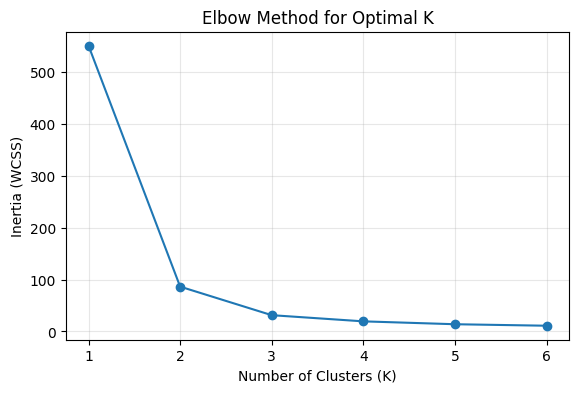

In [3]:
# Step 3: Elbow Method to choose optimal number of clusters (K)
inertia_values = []
for k in range(1, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X)
    inertia_values.append(km.inertia_)

plt.figure(figsize=(6.5, 4))
plt.plot(range(1, 7), inertia_values, marker="o")
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.grid(True, alpha=0.3)
plt.show()


In [4]:
# Step 4: Train K-Means with K = 3
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
clusters = kmeans.fit_predict(X)
centroids = kmeans.cluster_centers_

print("Cluster Inertia:", round(kmeans.inertia_, 2))
print("Silhouette Score:", round(silhouette_score(X, clusters), 4))


Cluster Inertia: 31.37
Silhouette Score: 0.6605


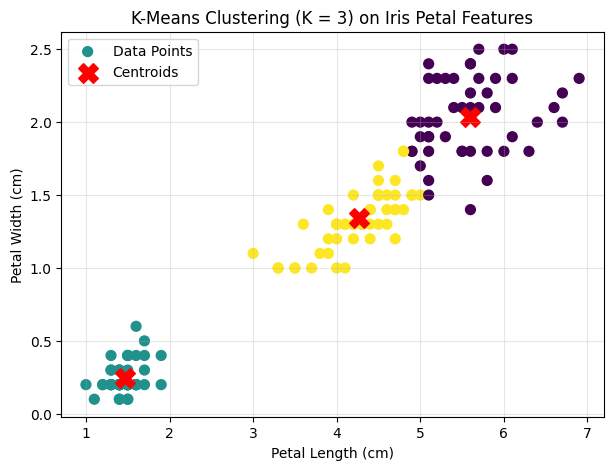

In [5]:
# Step 5: Plot the clusters and centroids
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=clusters, cmap="viridis", s=50, label="Data Points")
plt.scatter(centroids[:, 0], centroids[:, 1], c="red", marker="X", s=200, label="Centroids")
plt.title("K-Means Clustering (K = 3) on Iris Petal Features")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


## Conclusion
- The **Elbow Method** shows a clear bend at **$K = 3$**.
- K-Means successfully grouped the Iris flowers into 3 distinct clusters around their centroids without using labels.
